# Phase 5: Generation & Evaluation
In this notebook, we will use our fully trained VAE model to dream up **brand new molecules**! We will pick random points in the latent space, decode them, and then use `RDKit` to test if they are chemically valid and drug-like.

In [6]:
import os
os.environ['KMP_DUPLICATE_LIB_OK']='True'

import torch
import torch.nn as nn
import json
import numpy as np
from rdkit import Chem
from rdkit.Chem import Draw, QED
import matplotlib.pyplot as plt

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"Using device: {device}")

Using device: cpu


## 1. Rebuild the Model and Load the Vocabulary
We need to load our dictionary so we can translate numbers back to characters, and we need to rebuild the VAE brain so we can load the trained weights.

In [7]:
# Load Vocabulary
with open('../data/processed/vocab.json', 'r') as f:
    vocab_data = json.load(f)

int_to_char = vocab_data['int_to_char']
vocab_size = len(int_to_char)

# Exact same architecture as Step 4
class MolecularVAE(nn.Module):
    def __init__(self, vocab_size, embedding_dim=128, hidden_dim=256, latent_dim=64):
        super(MolecularVAE, self).__init__()
        self.embedding = nn.Embedding(vocab_size, embedding_dim)
        self.encoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_mu = nn.Linear(hidden_dim, latent_dim)
        self.fc_var = nn.Linear(hidden_dim, latent_dim)
        self.decoder_rnn = nn.GRU(embedding_dim, hidden_dim, batch_first=True)
        self.fc_z_to_hidden = nn.Linear(latent_dim, hidden_dim)
        self.fc_out = nn.Linear(hidden_dim, vocab_size)
        
    def decode_latent(self, z, max_len=120):
        # Start with the <SOS> token (which is index 1)
        hidden = self.fc_z_to_hidden(z).unsqueeze(0)
        current_input = torch.tensor([[1]], device=z.device) # <SOS>
        
        generated = []
        for _ in range(max_len):
            embedded = self.embedding(current_input)
            out, hidden = self.decoder_rnn(embedded, hidden)
            logits = self.fc_out(out)
            
            # Get the most likely next character
            # Fix: Use probability sampling instead of always picking the identical top character
            temperature = 1.0
            probs = torch.softmax(logits.squeeze(1) / temperature, dim=-1)
            next_char_idx = torch.multinomial(probs, 1)
            current_input = next_char_idx
            
            idx = next_char_idx.item()
            if idx == 2: # <EOS> token ends the string
                break
            generated.append(idx)
            
        return generated

# Initialize model and load the final weights!
model = MolecularVAE(vocab_size=vocab_size).to(device)
model.load_state_dict(torch.load('../models/vae_final.pt', map_location=device, weights_only=True))
model.eval() # Set model to evaluation mode
print("Model loaded successfully!")

Model loaded successfully!


## 2. Generating New SMILES
Let's randomly sample points from a normal distribution in our 64-dimensional latent space and ask the decoder to write the SMILES strings for them.

In [8]:
def generate_smiles(model, num_samples=100):
    generated_smiles = []
    with torch.no_grad():
        # Create random points in the latent space (mean 0, std 1)
        z_random = torch.randn(num_samples, 64).to(device)
        
        for i in range(num_samples):
            z = z_random[i].unsqueeze(0)
            char_indices = model.decode_latent(z)
            # Convert numbers back to string
            smiles = ''.join([int_to_char[str(idx)] for idx in char_indices])
            generated_smiles.append(smiles)
            
    return generated_smiles

print("Generating 100 new molecules...")
new_molecules = generate_smiles(model, num_samples=100)
print(f"Generated {len(new_molecules)} strings.")
print("\nFirst 5 generated strings:")
for s in new_molecules[:5]:
    print(s)

Generating 100 new molecules...
Generated 100 strings.

First 5 generated strings:
CC[C@@H](NC(=O)N[C@@H](C)c1c(C)noc1C)C(=O)N1CCCC[C@@H]1C

C=C[C@H](NC(=O)CCc1nncn1C1CC1)c1nc2ccsc2c(C)c1C

COC(=O)[C@H](C)OC(=O)c1sc(-c2ccc(F)cc2)nc1-c1ccnn1C

O=C(CSc1ccc2nccnc2c1)Nc1cccc(OC[C@H]2CCCO2)c1

O=C(N[C@@H](Cc1cccs1)C1CC1)c1cnn(-c2ccccc2)c1



## 3. Chemical Evaluation with RDKit
The AI doesn't know chemistry rules, it just knows patterns. We must use RDKit to check if the generated strings are valid molecules.

In [9]:
valid_molecules = []
valid_smiles = []
qed_scores = []

for smiles in new_molecules:
    # RDKit will return None if the molecule is chemically invalid
    mol = Chem.MolFromSmiles(smiles)
    if mol is not None:
        valid_molecules.append(mol)
        valid_smiles.append(smiles)
        qed_scores.append(QED.qed(mol))

validity_percentage = (len(valid_molecules) / len(new_molecules)) * 100
print(f"\nValidity: {validity_percentage:.2f}% of the generated strings are real, valid molecules!")

if valid_molecules:
    print(f"Average QED (Drug-likeness) Score: {np.mean(qed_scores):.4f}")


Validity: 80.00% of the generated strings are real, valid molecules!
Average QED (Drug-likeness) Score: 0.7200


[12:14:06] Explicit valence for atom # 6 N, 4, is greater than permitted
[12:14:06] SMILES Parse Error: extra close parentheses while parsing: O=C1CN(C(=O)[C@@H]2CC[C@H](C3=O)CCC3)C2)C(=O)N1c1ccc(-c2ccco2)nn1

[12:14:06] SMILES Parse Error: check for mistakes around position 40:
[12:14:06] CC[C@H](C3=O)CCC3)C2)C(=O)N1c1ccc(-c2ccco
[12:14:06] ~~~~~~~~~~~~~~~~~~~~^
[12:14:06] SMILES Parse Error: Failed parsing SMILES 'O=C1CN(C(=O)[C@@H]2CC[C@H](C3=O)CCC3)C2)C(=O)N1c1ccc(-c2ccco2)nn1
' for input: 'O=C1CN(C(=O)[C@@H]2CC[C@H](C3=O)CCC3)C2)C(=O)N1c1ccc(-c2ccco2)nn1
'
[12:14:06] SMILES Parse Error: unclosed ring for input: 'CCOC(=O)N1CCC([NH+](C[C@H]2C[NH2+]C32)C[NH2+]CC1)C1CC1
'
[12:14:06] Can't kekulize mol.  Unkekulized atoms: 3 21 22
[12:14:06] Can't kekulize mol.  Unkekulized atoms: 3 21 22
[12:14:06] SMILES Parse Error: unclosed ring for input: 'C[C@H](NC(=S)Nc1nc2c(C)nc3ncnc4c2C)c(C)n1-c1ccccc1Cl
'
[12:14:06] SMILES Parse Error: unclosed ring for input: 'C[C@@]12CC[C@H]3[NH+]=N1=c4cccc

## 4. Visualizing the Generated Molecules
Let's actually look at what our AI dreamed up!

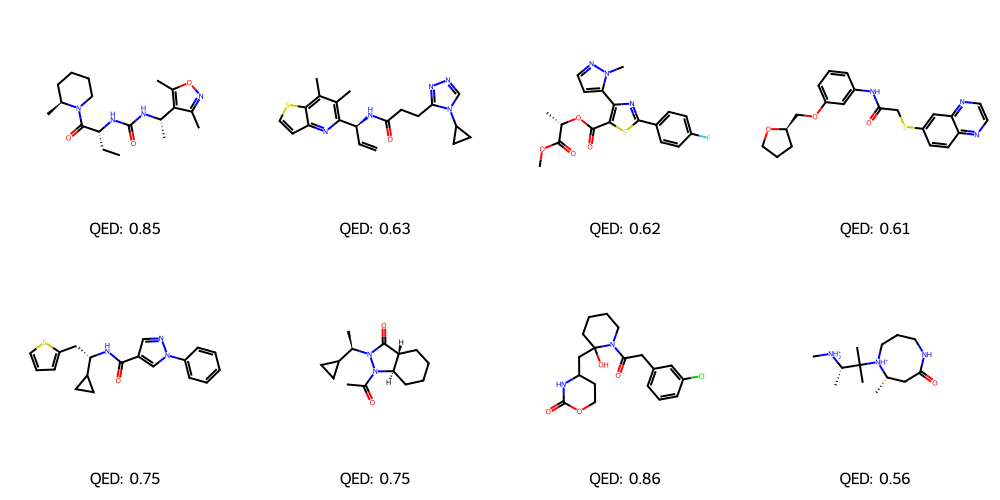

In [10]:
if valid_molecules:
    # Draw up to 8 valid molecules
    mols_to_draw = valid_molecules[:8]
    img = Draw.MolsToGridImage(mols_to_draw, molsPerRow=4, subImgSize=(250, 250), 
                               legends=[f"QED: {qed_scores[i]:.2f}" for i in range(len(mols_to_draw))])
    display(img)
else:
    print("No valid molecules generated to draw. Try generating a larger batch!")